# BLEVE Overpressure Prediction
Tabular regression: predict the target pressure (bar) at a sensor from tank, liquid, obstacle and sensor-position features. Compares ElasticNet, NuSVR, XGBoost, CatBoost and LightGBM, then blends the three tree models into a weighted ensemble.

Python Imports

In [68]:
import sys
import torch
import numpy as np
import pandas as pd

# Uncomment if packages not found
#!pip install xgboost
#!pip install catboost
#!pip install lightgbm

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_percentage_error, r2_score, mean_squared_error

from sklearn.linear_model import ElasticNet
from sklearn.svm import NuSVR
from xgboost import XGBRegressor
import xgboost
from catboost import CatBoostRegressor
import catboost
from lightgbm import LGBMRegressor
import lightgbm

SEED = 42

print("Python:", sys.version)
print("XGBoost version:", xgboost.__version__)
print("CatBoost version:", catboost.__version__)
print("LightGBM version:", lightgbm.__version__)

Python: 3.11.15 | packaged by Anaconda, Inc. | (main, Mar 11 2026, 17:12:15) [MSC v.1942 64 bit (AMD64)]
XGBoost version: 3.2.0
CatBoost version: 1.2.8
LightGBM version: 4.6.0


GPU Support Detection - Drastically Speed Up Learning Rates If Available

In [69]:
try:
    GPU_AVAILABLE = torch.cuda.is_available()
except:
    GPU_AVAILABLE = False

print("GPU Available:", GPU_AVAILABLE)

# XGBoost settings
if GPU_AVAILABLE:
    XGB_DEVICE = "cuda"
else:
    XGB_DEVICE = "cpu"

# CatBoost settings
if GPU_AVAILABLE:
    CATBOOST_TASK_TYPE = "GPU"
    CATBOOST_DEVICES = "0"
else:
    CATBOOST_TASK_TYPE = "CPU"
    CATBOOST_DEVICES = None

print("XGBoost Device:", XGB_DEVICE)
print("CatBoost Task Type:", CATBOOST_TASK_TYPE)
print("CatBoost Devices:", CATBOOST_DEVICES)

GPU Available: True
XGBoost Device: cuda
CatBoost Task Type: GPU
CatBoost Devices: 0


Load Testing & Training Data

In [70]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
train_original = train.copy()
test_original = test.copy()
TARGET = "Target Pressure (bar)"
ID_COL = "ID"

#Pressure Column name used multiple times - defined as constant for easy updates
PRESSURE_COL = "Tank Failure Pressure (bar)"

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (10050, 25)
Test shape: (3203, 24)


## Cleaning Stage
Create Cleaning Functions

In [ ]:
# Function to clean empty values and correct spelling in the Status column
def clean_empty_vals_and_spelling(x):
    """
    Cleans empty values and corrects spelling in the Status column.
    """
    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if any(word in x for word in ["super", "saper", "heat"]):
        return "Superheated"
    elif any(word in x for word in ["sub", "cool"]):
        return "Subcooled"
    else:
        return np.nan

# Function to clean the raw data, including handling invalid pressure values and removing rows with too many missing values or missing target
def clean_raw_data(df, is_training_data=True):
    """
    Cleans the raw data by handling invalid pressure values, correcting spelling in the Status column, and removing rows with too many missing values or missing target (for training data).
    """
    df = df.copy()

    # Clean empty values and correct spelling in the Status column
    df["Status"] = df["Status"].apply(clean_empty_vals_and_spelling)

    # Flag physically invalid pressure values
    df["Invalid Pressure"] = (
        (df[PRESSURE_COL] <= 0) |
        (df[PRESSURE_COL] > 50)
    ).astype(int)

    # Treat invalid pressure as missing
    df.loc[df["Invalid Pressure"] == 1, PRESSURE_COL] = np.nan

    # Remove duplicate rows based on all columns except ID
    df = df.drop_duplicates(
    subset=df.columns.difference(["ID"])
    )

    # For training data, remove rows with too many missing values or missing target
    if is_training_data:
        rows_before = len(df)

        # Remove rows with 2 or more missing values
        df = df[df.isna().sum(axis=1) <= 1]

        # Remove rows missing target
        df = df.dropna(subset=[TARGET])

        print(f"Rows before cleaning: {rows_before}")
        print(f"Rows after cleaning: {len(df)}")
        print(f"Rows removed: {rows_before - len(df)}")

    return df

Clean Training and Testing Data of Missing Values or Spelling Errors

In [72]:
train_clean = clean_raw_data(train_original, is_training_data=True)
test_clean = clean_raw_data(test_original, is_training_data=False)

print("Train shape:", train_clean.shape)
print("Test shape:", test_clean.shape)
print(train_clean[PRESSURE_COL].describe())

Rows before cleaning: 10000
Rows after cleaning: 9990
Rows removed: 10
Train shape: (9990, 26)
Test shape: (3203, 25)
count    9940.000000
mean       22.959989
std        10.545147
min         4.920000
25%        13.690000
50%        22.745000
75%        32.052500
max        42.180000
Name: Tank Failure Pressure (bar), dtype: float64


## Preprocessing Stage
Split target feature (Target Pressure) from data sets and identifiy and drop ids

In [73]:
X = train_clean.drop(columns=[TARGET])
y = train_clean[TARGET]

test_ids = test_clean[ID_COL]
drop_cols = [ID_COL]

Identify features and split them based on being numerical or categorical

In [74]:
categorical_features = [
    "Status",
    "Sensor Position Side"
]

raw_numeric_features = [
    col for col in X.columns
    if col not in categorical_features + drop_cols
]

print("Raw numeric features:", len(raw_numeric_features))
print("Categorical features:", categorical_features)

Raw numeric features: 22
Categorical features: ['Status', 'Sensor Position Side']


Impute numeric features that are empty or NaN before feature engineering using KNN with 5 neighbours

Training data is fitted and transformed<br>
Testing data is only transformed if required to prevent learning from test data

In [75]:
numeric_imputer = KNNImputer(n_neighbors=5)

X_numeric_imputed = pd.DataFrame(
    numeric_imputer.fit_transform(X[raw_numeric_features]),
    columns=raw_numeric_features,
    index=X.index
)

test_numeric_imputed = pd.DataFrame(
    numeric_imputer.transform(test_clean[raw_numeric_features]),
    columns=raw_numeric_features,
    index=test_clean.index
)

For testing / developement purposes - Function to track imputations on dataframes

In [ ]:
def track_imputations(original_df,cleaned_df,imputed_df,numeric_features,dataset_name="Dataset"):
    """
    Tracks which values were imputed and returns:
    - detailed comparison dataframe
    - summary dataframe
    """
    missing_mask = cleaned_df[numeric_features].isna()

    imputation_records = []

    # Loop through each numeric feature and record imputed values along with original values if available
    for col in numeric_features:
        rows = missing_mask[col]

        for idx in cleaned_df.index[rows]:

            # Get original value safely
            if (
                original_df is not None and
                col in original_df.columns and
                idx in original_df.index
            ):
                original_value = original_df.loc[idx, col]
            else:
                original_value = np.nan

            imputation_records.append({
                "Dataset": dataset_name,
                "Row Index": idx,
                "Feature": col,
                "Original Value": original_value,
                "After Cleaning": cleaned_df.loc[idx, col],
                "After Imputation": imputed_df.loc[idx, col]
            })

    comparison_df = pd.DataFrame(imputation_records)

    # If no imputed values, print no values found and return None for summary_df to indicate no imputation was needed
    if comparison_df.empty:

        print(f"No imputed values found in {dataset_name} dataset.")
        summary_df = None
    # If imputed values found, create summary dataframe counting number of imputations per feature
    else:
        summary_df = (
            comparison_df
            .groupby("Feature")
            .size()
            .reset_index(name="Number of Imputed Values")
            .sort_values("Number of Imputed Values", ascending=False)
        )

    return comparison_df, summary_df

For testing / developement purposes - Track training imputations

In [77]:
train_comparison_df, train_summary_df = track_imputations(
    original_df=train_original,
    cleaned_df=X,
    imputed_df=X_numeric_imputed,
    numeric_features=raw_numeric_features,
    dataset_name="Train"
)
if train_summary_df is not None:
    print(train_summary_df)

                           Feature  Number of Imputed Values
4      Tank Failure Pressure (bar)                        50
0   Liquid Boiling Temperature (K)                        20
1   Liquid Critical Pressure (bar)                        20
2  Liquid Critical Temperature (K)                        20
3           Liquid Temperature (K)                        20
5           Vapour Temperature (K)                        20


For testing / developement purposes - Track testing imputations

In [78]:
test_comparison_df, test_summary_df = track_imputations(
    original_df=test_original,
    cleaned_df=test_clean,
    imputed_df=test_numeric_imputed,
    numeric_features=raw_numeric_features,
    dataset_name="Test"
)

if test_summary_df is not None:
    print(test_summary_df)

No imputed values found in Test dataset.


Rebuild Data Sets after Imputation and Split of Numerical and Categorical Features

In [79]:
X_base = X_numeric_imputed.copy()
X_base[categorical_features] = X[categorical_features].values
X_base["Invalid Pressure"] = X["Invalid Pressure"].values

test_base = test_numeric_imputed.copy()
test_base[categorical_features] = test_clean[categorical_features].values
test_base["Invalid Pressure"] = test_clean["Invalid Pressure"].values

### Feature Engineering

In [ ]:
def add_engineered_features(df):
    """
    Adds engineered features to the dataframe based on domain knowledge and feature interactions.
     - Tank geometry features (volume, surface area approximation, width-length ratio)
     - Vapour/height relationships (vapour height ratio, BLEVE height ratio)
     - Temperature differences (liquid-vapour temp difference, liquid-boiling temp difference)
     - Obstacle geometry (area, volume)
     - Distance & pressure features (inverse distance, pressure-distance interactions)
     - Interaction features (pressure-volume, volume-distance, pressure-temp, volume-temp)
     - Sensor distance from origin
     - Trigonometric transformations of obstacle angle
     - Squared terms for pressure and distance
    """
    df = df.copy()
    eps = 1e-6

    # Tank Geometry
    df["Tank Volume"] = (
        df["Tank Width (m)"] *
        df["Tank Length (m)"] *
        df["Tank Height (m)"]
    )

    df["Tank Width Length Ratio"] = (
        df["Tank Width (m)"] /
        (df["Tank Length (m)"] + eps)
    )

    df["Tank Surface Area Approx"] = 2 * (
        df["Tank Width (m)"] * df["Tank Length (m)"] +
        df["Tank Width (m)"] * df["Tank Height (m)"] +
        df["Tank Length (m)"] * df["Tank Height (m)"]
    )

    # Vapour / Height relationships
    df["Vapour Height Ratio"] = (
        df["Vapour Height (m)"] /
        (df["Tank Height (m)"] + eps)
    )

    df["BLEVE Height Ratio"] = (
        df["BLEVE Height (m)"] /
        (df["Tank Height (m)"] + eps)
    )

    # Temperature Features
    df["Liquid Vapour Temp Difference"] = (
        df["Liquid Temperature (K)"] -
        df["Vapour Temperature (K)"]
    )

    df["Liquid Boiling Temp Difference"] = (
        df["Liquid Temperature (K)"] -
        df["Liquid Boiling Temperature (K)"]
    )

    # Obstacle Geometry
    df["Obstacle Area"] = (
        df["Obstacle Width (m)"] *
        df["Obstacle Height (m)"]
    )

    df["Obstacle Volume"] = (
        df["Obstacle Width (m)"] *
        df["Obstacle Height (m)"] *
        df["Obstacle Thickness (m)"]
    )

    # Distance & Pressure features
    df["Inverse Distance"] = (
        1 / (df["Obstacle Distance to BLEVE (m)"] + eps)
    )

    df["Pressure Distance Interaction"] = (
        df["Tank Failure Pressure (bar)"] /
        (df["Obstacle Distance to BLEVE (m)"] + eps)
    )

    df["Pressure Distance Squared"] = (
        df["Tank Failure Pressure (bar)"] /
        ((df["Obstacle Distance to BLEVE (m)"] ** 2) + eps)
    )

    # Interaction features
    df["Pressure Volume Interaction"] = (
        df["Tank Failure Pressure (bar)"] *
        df["Tank Volume"]
    )

    df["Volume Distance Interaction"] = (
        df["Tank Volume"] /
        (df["Obstacle Distance to BLEVE (m)"] + eps)
    )

    df["Pressure Temp Interaction"] = (
        df["Tank Failure Pressure (bar)"] *
        df["Vapour Temperature (K)"]
    )

    df["Volume Temp Interaction"] = (
        df["Tank Volume"] *
        df["Vapour Temperature (K)"]
    )

    df["Pressure Squared"] = (
        df["Tank Failure Pressure (bar)"] ** 2
    )

    df["Distance Squared"] = (
        df["Obstacle Distance to BLEVE (m)"] ** 2
    )

    # Sensor distance
    df["Sensor Distance"] = np.sqrt(
        df["Sensor Position x"]**2 +
        df["Sensor Position y"]**2 +
        df["Sensor Position z"]**2
    )

    # Angle transformation
    angle_rad = np.deg2rad(df["Obstacle Angle"])
    df["Obstacle Angle sin"] = np.sin(angle_rad)
    df["Obstacle Angle cos"] = np.cos(angle_rad)

    return df

Add feature engineering to Dataframes

In [81]:
X_final = add_engineered_features(X_base)
test_final = add_engineered_features(test_base)

print("Final train shape:", X_final.shape)
print("Final test shape:", test_final.shape)

Final train shape: (9990, 45)
Final test shape: (3203, 45)


Final Preprocessing

In [ ]:
final_categorical_features = categorical_features

final_numeric_features = [
    col for col in X_final.columns
    if col not in final_categorical_features
]

# Define preprocessing pipelines for numeric and categorical features

# Numeric features are scaled using StandardScaler,
numeric_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler())
])
# Categorical features are encoded using OneHotEncoder with handle_unknown="ignore" to prevent errors from unseen categories in test data
categorical_pipeline = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
# Combine numeric and categorical pipelines into a ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, final_numeric_features),
    ("cat", categorical_pipeline, final_categorical_features)
])

## Train Validation Split

In [83]:
y_log = np.log1p(y)

# KFold for tuning
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Holdout split for final validation
X_train, X_val, y_train_log, y_val_log = train_test_split(
    X_final,
    y_log,
    test_size=0.2,
    random_state=SEED
)

_, _, y_train_actual, y_val_actual = train_test_split(
    X_final,
    y,
    test_size=0.2,
    random_state=SEED
)

## Model Evaluation Functions

In [ ]:
# Function to calculate negative MAPE on actual values for use as a scorer in hyperparameter tuning
def neg_actual_mape_scorer(estimator, X, y_log_true):
    """
    Calculates negative MAPE on actual values for use as a scorer in hyperparameter tuning.
    """
    y_true = np.expm1(y_log_true)
    y_pred = np.expm1(estimator.predict(X))
    y_pred = np.clip(y_pred, 0.01, None)
    return -mean_absolute_percentage_error(y_true, y_pred)

# Function to evaluate model performance on training and validation sets, including reversing log transformation and calculating metrics
def evaluate_model(model, X_train, X_val, y_train_actual, y_val_actual, model_name, log_target=True, clip_min=0.01):
    """
    Evaluates model performance on training and validation sets by generating predictions, reversing log transformation if required, preventing zero/negative predictions, and calculating MAPE, R2, and RMSE metrics.
    Returns a results dataframe and the predictions for training and validation sets.
    """
    # Generate predictions
    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    # Reverse log transformation if required
    if log_target:
        train_preds = np.expm1(train_preds)
        val_preds = np.expm1(val_preds)

    # Prevent zero/negative predictions
    train_preds = np.clip(train_preds, clip_min, None)
    val_preds = np.clip(val_preds, clip_min, None)

    # Metrics
    train_mape = mean_absolute_percentage_error(
        y_train_actual,
        train_preds
    )

    val_mape = mean_absolute_percentage_error(
        y_val_actual,
        val_preds
    )

    train_r2 = r2_score(
        y_train_actual,
        train_preds
    )

    val_r2 = r2_score(
        y_val_actual,
        val_preds
    )

    val_rmse = np.sqrt(
        mean_squared_error(
            y_val_actual,
            val_preds
        )
    )

    # Results dataframe
    results_df = pd.DataFrame([{
        "Model": model_name,
        "Train MAPE": train_mape,
        "Validation MAPE": val_mape,
        "Train R2": train_r2,
        "Validation R2": val_r2,
        "Validation RMSE": val_rmse
    }])

    return results_df, train_preds, val_preds

## ElasticNet Pipeline - Linear Regression Model

In [85]:
elastic_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", ElasticNet(
        max_iter=10000,
        random_state=SEED
    ))
])
elastic_pipeline.fit(X_train, y_train_log)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


ElasticNet Hyperparameter Tuning

In [ ]:
elastic_tuning_params= {
    "model__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 5, 10],
    "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
}

elastic_search = RandomizedSearchCV(
    estimator=elastic_pipeline,
    param_distributions=elastic_tuning_params,
    n_iter=12,
    scoring=neg_actual_mape_scorer,
    cv=3,
    verbose=2,
    random_state=SEED,
    n_jobs=-1
)

elastic_search.fit(X_train, y_train_log)

print("Best ElasticNet Parameters:")
print(elastic_search.best_params_)

print("Best ElasticNet CV MAPE:")
print(-elastic_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best ElasticNet Parameters:
{'model__l1_ratio': 0.7, 'model__alpha': 0.001}
Best ElasticNet CV MAPE:
0.49410730888165744


ElaticNet Final Validation

In [87]:
best_elastic = elastic_search.best_estimator_

elastic_results, elastic_train_preds, elastic_val_preds = evaluate_model(
    model=best_elastic,
    X_train=X_train,
    X_val=X_val,
    y_train_actual=y_train_actual,
    y_val_actual=y_val_actual,
    model_name="ElasticNet"
)

elastic_results

,Model,Train MAPE,Validation MAPE,Train R2,Validation R2,Validation RMSE
0,ElasticNet,0.49132,0.484202,0.590341,0.557017,0.367393


## NuSVR Pipeline - Support Vector Regression Model

In [88]:
nusvr_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", NuSVR(
        kernel="rbf",
        C=10,
        nu=0.2,
        gamma="scale"
    ))
])

nusvr_pipeline.fit(X_train, y_train_log)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


NuSVR Hyperparameter Tuning - Commented Out to Save time as no change in evaluation scores (Already well trained model - no need for tuning)

In [ ]:
nusvr_tuning_params= {
    "model__C": [1, 5, 10, 20, 50],
    "model__nu": [0.1, 0.2, 0.3, 0.5],
    "model__gamma": ["scale", "auto", 0.01, 0.05, 0.1],
}

nusvr_search = RandomizedSearchCV(
    estimator=nusvr_pipeline,
    param_distributions=nusvr_tuning_params,
    n_iter=10,
    scoring=neg_actual_mape_scorer,
    cv=2,
    verbose=2,
    random_state=SEED,
    n_jobs=-1
)

nusvr_search.fit(X_train, y_train_log)

print("Best parameters:")
print(nusvr_search.best_params_)

print("Best CV MAPE on original target scale:")
print(-nusvr_search.best_score_)

Fitting 2 folds for each of 10 candidates, totalling 20 fits
Best parameters:
{'model__nu': 0.3, 'model__gamma': 'scale', 'model__C': 5}
Best CV MAPE on original target scale:
0.2194030849118344


NuSVR Final Validation

In [90]:
nusvr_results, nusvr_train_preds, nusvr_val_preds = evaluate_model(
    model=nusvr_pipeline,
    X_train=X_train,
    X_val=X_val,
    y_train_actual=y_train_actual,
    y_val_actual=y_val_actual,
    model_name="NuSVR"
)

nusvr_results

,Model,Train MAPE,Validation MAPE,Train R2,Validation R2,Validation RMSE
0,NuSVR,0.133342,0.179972,0.966014,0.906066,0.16918


## XGBoost Pipeline - Extreme Gradient Boosted Decision Tree

In [91]:
xgb_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        tree_method="hist",
        device=XGB_DEVICE,
        random_state=SEED,
        n_jobs=-1
    ))
])
xgb_pipeline.fit(X_train, y_train_log)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


XGBoost Hyperparameter Tuning

In [ ]:
xgb_tuning_params= {
    "model__n_estimators": [400, 600, 800, 1000, 1200, 1500],
    "model__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.08],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__min_child_weight": [1, 2, 3, 5, 7],
    "model__subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "model__reg_alpha": [0, 0.001, 0.01, 0.1, 1],
    "model__reg_lambda": [0.5, 1, 2, 5, 10],
    "model__gamma": [0, 0.001, 0.01, 0.1, 0.5]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_tuning_params,
    n_iter=50,
    scoring=neg_actual_mape_scorer,
    cv=kf,
    verbose=2,
    random_state=SEED,
    n_jobs=1
)

xgb_search.fit(X_train, y_train_log)

print("Best parameters:")
print(xgb_search.best_params_)

print("Best CV MAPE on original target scale:")
print(-xgb_search.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END model__colsample_bytree=1.0, model__gamma=0.1, model__learning_rate=0.05, model__max_depth=3, model__min_child_weight=5, model__n_estimators=1200, model__reg_alpha=1, model__reg_lambda=2, model__subsample=0.6; total time=   0.7s
[CV] END model__colsample_bytree=1.0, model__gamma=0.1, model__learning_rate=0.05, model__max_depth=3, model__min_child_weight=5, model__n_estimators=1200, model__reg_alpha=1, model__reg_lambda=2, model__subsample=0.6; total time=   0.7s
[CV] END model__colsample_bytree=1.0, model__gamma=0.1, model__learning_rate=0.05, model__max_depth=3, model__min_child_weight=5, model__n_estimators=1200, model__reg_alpha=1, model__reg_lambda=2, model__subsample=0.6; total time=   0.7s
[CV] END model__colsample_bytree=1.0, model__gamma=0.1, model__learning_rate=0.05, model__max_depth=3, model__min_child_weight=5, model__n_estimators=1200, model__reg_alpha=1, model__reg_lambda=2, model__subsample=0.6; total

Tuned XGBoost Validation

In [93]:
best_xgb = xgb_search.best_estimator_

xgb_results, xgb_train_preds, xgb_val_preds = evaluate_model(
    model=best_xgb,
    X_train=X_train,
    X_val=X_val,
    y_train_actual=y_train_actual,
    y_val_actual=y_val_actual,
    model_name="Tuned XGBoost + Log Target"
)

xgb_results

,Model,Train MAPE,Validation MAPE,Train R2,Validation R2,Validation RMSE
0,Tuned XGBoost + Log Target,0.05838,0.11988,0.997676,0.949112,0.124522


## CatBoost Pipeline - Categorical Boosting Decesion Tree

In [94]:
catboost_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", CatBoostRegressor(
        loss_function="RMSE",
        eval_metric="RMSE",
        random_seed=SEED,
        verbose=0,
        task_type=CATBOOST_TASK_TYPE,
        devices=CATBOOST_DEVICES,
        bootstrap_type="Bernoulli",
        thread_count=-1
    ))
])

CatBoost Hyperparameter Tuning - Uses two steps to increase speed while improving accuracy

In [ ]:
# Stage 1: coarse tuning with 2-fold CV to narrow down the hyperparameter space
catboost_stage1_tuning_params= {
    "model__iterations": [500, 800, 1200],
    "model__learning_rate": [0.02, 0.03, 0.05],
    "model__depth": [4, 5, 6],
    "model__l2_leaf_reg": [3, 5, 7, 10],
    "model__random_strength": [0, 0.5, 1],
    "model__subsample": [0.8, 0.9, 1.0]
}

catboost_stage1_search = RandomizedSearchCV(
    estimator=catboost_pipeline,
    param_distributions=catboost_stage1_tuning_params,
    n_iter=8,
    cv=2,
    scoring=neg_actual_mape_scorer,
    verbose=2,
    random_state=SEED,
    n_jobs=1,
    error_score="raise"
)

catboost_stage1_search.fit(X_train, y_train_log)

print("Stage 1 best parameters:")
print(catboost_stage1_search.best_params_)

print("Stage 1 best CV MAPE on original target scale:")
print(-catboost_stage1_search.best_score_)

best_stage1_params = catboost_stage1_search.best_params_

def neighbourhood(value, candidates, radius=1):
    idx = candidates.index(value)
    low = max(0, idx - radius)
    high = min(len(candidates), idx + radius + 1)
    return candidates[low:high]

# Stage 2: search near the best coarse result with 3-fold CV.
iteration_candidates = [500, 800, 1200, 1600]
learning_rate_candidates = [0.015, 0.02, 0.03, 0.05]
depth_candidates = [4, 5, 6, 7]
l2_candidates = [1, 3, 5, 7, 10, 15]
random_strength_candidates = [0, 0.5, 1, 2]
subsample_candidates = [0.7, 0.8, 0.9, 1.0]

catboost_stage2_tuning_params= {
    "model__iterations": neighbourhood(best_stage1_params["model__iterations"], iteration_candidates),
    "model__learning_rate": neighbourhood(best_stage1_params["model__learning_rate"], learning_rate_candidates),
    "model__depth": neighbourhood(best_stage1_params["model__depth"], depth_candidates),
    "model__l2_leaf_reg": neighbourhood(best_stage1_params["model__l2_leaf_reg"], l2_candidates),
    "model__random_strength": neighbourhood(best_stage1_params["model__random_strength"], random_strength_candidates),
    "model__subsample": neighbourhood(best_stage1_params["model__subsample"], subsample_candidates)
}

catboost_search = RandomizedSearchCV(
    estimator=catboost_pipeline,
    param_distributions=catboost_stage2_tuning_params,
    n_iter=15,
    cv=3,
    scoring=neg_actual_mape_scorer,
    verbose=2,
    random_state=43,
    n_jobs=1,
    error_score="raise"
)

catboost_search.fit(X_train, y_train_log)

print("Stage 2 best parameters:")
print(catboost_search.best_params_)

print("Stage 2 best CV MAPE on original target scale:")
print(-catboost_search.best_score_)

Fitting 2 folds for each of 8 candidates, totalling 16 fits
[CV] END model__depth=4, model__iterations=500, model__l2_leaf_reg=10, model__learning_rate=0.05, model__random_strength=0.5, model__subsample=0.8; total time=   4.5s
[CV] END model__depth=4, model__iterations=500, model__l2_leaf_reg=10, model__learning_rate=0.05, model__random_strength=0.5, model__subsample=0.8; total time=   4.3s
[CV] END model__depth=5, model__iterations=800, model__l2_leaf_reg=3, model__learning_rate=0.02, model__random_strength=0.5, model__subsample=0.8; total time=   7.6s
[CV] END model__depth=5, model__iterations=800, model__l2_leaf_reg=3, model__learning_rate=0.02, model__random_strength=0.5, model__subsample=0.8; total time=   7.1s
[CV] END model__depth=6, model__iterations=800, model__l2_leaf_reg=10, model__learning_rate=0.05, model__random_strength=0.5, model__subsample=1.0; total time=   7.9s
[CV] END model__depth=6, model__iterations=800, model__l2_leaf_reg=10, model__learning_rate=0.05, model__ra

Tuned CatBoost Validation

In [96]:
best_catboost = catboost_search.best_estimator_

cat_results, cat_train_preds, cat_val_preds = evaluate_model(
    model=best_catboost,
    X_train=X_train,
    X_val=X_val,
    y_train_actual=y_train_actual,
    y_val_actual=y_val_actual,
    model_name="Tuned CatBoost + Log Target"
)

cat_results

,Model,Train MAPE,Validation MAPE,Train R2,Validation R2,Validation RMSE
0,Tuned CatBoost + Log Target,0.124002,0.143646,0.979728,0.945731,0.128592


## LightGBM Pipeline - Light Gradient Boosting Machine Decision Tree

In [97]:
lightgbm_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),

    ("model", LGBMRegressor(
        objective="regression",
        random_state=SEED,
        n_jobs=-1,
        verbose=-1
    ))
])

LightGBM Hyperparameter Tuning

In [ ]:
lightgbm_tuning_params= {
    "model__n_estimators": [300, 500, 800, 1000, 1200],
    "model__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.08],
    "model__max_depth": [-1, 3, 5, 7, 9],
    "model__num_leaves": [15, 31, 63, 127],
    "model__min_child_samples": [5, 10, 20, 30, 50],
    "model__subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "model__reg_alpha": [0, 0.001, 0.01, 0.1, 1],
    "model__reg_lambda": [0.5, 1, 2, 5, 10]
}

lightgbm_search = RandomizedSearchCV(
    estimator=lightgbm_pipeline,
    param_distributions=lightgbm_tuning_params,
    n_iter=30,
    scoring=neg_actual_mape_scorer,
    cv=kf,
    verbose=2,
    random_state=20,
    n_jobs=-1
)

lightgbm_search.fit(X_train, y_train_log)

print("Best LightGBM Parameters:")
print(lightgbm_search.best_params_)

print("Best LightGBM CV MAPE:")
print(-lightgbm_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best LightGBM Parameters:
{'model__subsample': 0.6, 'model__reg_lambda': 0.5, 'model__reg_alpha': 0, 'model__num_leaves': 63, 'model__n_estimators': 800, 'model__min_child_samples': 20, 'model__max_depth': 9, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}
Best LightGBM CV MAPE:
0.11989126229256061


Tuned LightGBM Validation

In [99]:
best_lightgbm = lightgbm_search.best_estimator_

lightgbm_results, lgb_train_preds, lgb_val_preds = evaluate_model(
    model=best_lightgbm,
    X_train=X_train,
    X_val=X_val,
    y_train_actual=y_train_actual,
    y_val_actual=y_val_actual,
    model_name="Tuned LightGBM + Log Target"
)

lightgbm_results

site-packages/sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
site-packages/sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,Train MAPE,Validation MAPE,Train R2,Validation R2,Validation RMSE
0,Tuned LightGBM + Log Target,0.040546,0.107139,0.998732,0.948575,0.125177


## Model Comparisons

In [100]:
comparison_df = pd.concat([
    elastic_results,
    nusvr_results,
    xgb_results,
    cat_results,
    lightgbm_results
], ignore_index=True)

comparison_df = comparison_df.sort_values(
    by="Validation MAPE",
    ascending=True
)

comparison_df

,Model,Train MAPE,Validation MAPE,Train R2,Validation R2,Validation RMSE
4,Tuned LightGBM + Log Target,0.040546,0.107139,0.998732,0.948575,0.125177
2,Tuned XGBoost + Log Target,0.058380,0.119880,0.997676,0.949112,0.124522
3,Tuned CatBoost + Log Target,0.124002,0.143646,0.979728,0.945731,0.128592
1,NuSVR,0.133342,0.179972,0.966014,0.906066,0.169180
0,ElasticNet,0.491320,0.484202,0.590341,0.557017,0.367393


Train Final Models

In [101]:
#Train final NuSVR model on all data with log target (no hyperparameter tuning for NuSVR)
final_nusvr_pipeline = nusvr_pipeline
final_nusvr_pipeline.fit(X_final, y_log)

# Train final XGBoost model on all data with log target and best hyperparameters from tuning
final_xgb_pipeline = xgb_search.best_estimator_
final_xgb_pipeline.fit(X_final, np.log1p(y))

# Train final CatBoost model on all data with log target and best hyperparameters from tuning
final_cat_pipeline = catboost_search.best_estimator_
final_cat_pipeline.fit(X_final, np.log1p(y))

# Train final LightGBM model on all data with log target and best hyperparameters from tuning
final_lgbm_pipeline = lightgbm_search.best_estimator_
final_lgbm_pipeline.fit(X_final, np.log1p(y))

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Predict Test Sets with final models and prepare submission files

In [102]:
nusvr_test_preds_log = final_nusvr_pipeline.predict(test_final)
nusvr_test_preds = np.expm1(nusvr_test_preds_log)
nusvr_test_preds = np.clip(nusvr_test_preds, 0.01, None)

xgb_test_preds_log = final_xgb_pipeline.predict(test_final)
xgb_test_preds = np.expm1(xgb_test_preds_log)
xgb_test_preds = np.clip(xgb_test_preds, 0.01, None)

cat_test_preds_log = final_cat_pipeline.predict(test_final)
cat_test_preds = np.expm1(cat_test_preds_log)
cat_test_preds = np.clip(cat_test_preds, 0.01, None)

lgb_test_preds_log = final_lgbm_pipeline.predict(test_final)
lgb_test_preds = np.expm1(lgb_test_preds_log)
lgb_test_preds = np.clip(lgb_test_preds, 0.01, None)

site-packages/sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


## Create Ensemble from XGB, CAT, LGB final models

In [103]:
# Ensemble weights - based on validation performance and intuition about model strengths
XGB_WEIGHT = 0.80
CAT_WEIGHT = 0.15
LGB_WEIGHT = 0.05

# Generate ensemble predictions for test set
ensemble_preds = (
    xgb_test_preds * XGB_WEIGHT +
    cat_test_preds * CAT_WEIGHT +
    lgb_test_preds * LGB_WEIGHT
)

# Generate ensemble predictions for validation set
ensemble_val_preds = (
    xgb_val_preds * XGB_WEIGHT +
    cat_val_preds * CAT_WEIGHT +
    lgb_val_preds * LGB_WEIGHT
)

# Metrics for ensemble on validation set
ensemble_val_mape = mean_absolute_percentage_error(
    y_val_actual,
    ensemble_val_preds
)

ensemble_val_r2 = r2_score(
    y_val_actual,
    ensemble_val_preds
)

ensemble_val_rmse = np.sqrt(
    mean_squared_error(
        y_val_actual,
        ensemble_val_preds
    )
)


# Print Ensemble results
print("\n========================")
print("ENSEMBLE RESULTS")
print("========================")

print(f"XGBoost Weight: {XGB_WEIGHT}")
print(f"CatBoost Weight: {CAT_WEIGHT}")
print(f"LightGBM Weight: {LGB_WEIGHT}")

print(f"\nValidation MAPE: {ensemble_val_mape:.6f}")
print(f"Validation R2: {ensemble_val_r2:.6f}")
print(f"Validation RMSE: {ensemble_val_rmse:.6f}")


ENSEMBLE RESULTS
XGBoost Weight: 0.8
CatBoost Weight: 0.15
LightGBM Weight: 0.05

Validation MAPE: 0.116731
Validation R2: 0.950196
Validation RMSE: 0.123189


## Create Submission Files

In [ ]:
# NuSVR submission
nusvr_submission = pd.DataFrame({
    "ID": test_ids,
    "Target Pressure (bar)": nusvr_test_preds
})
nusvr_submission.to_csv("NuSVR_Predictions.csv", index=False)

# XGBoost submission
xgb_submission = pd.DataFrame({
    "ID": test_ids,
    "Target Pressure (bar)": xgb_test_preds
})
xgb_submission.to_csv("XGBoost_Predictions.csv", index=False)

# CatBoost submission
cat_submission = pd.DataFrame({
    "ID": test_ids,
    "Target Pressure (bar)": cat_test_preds
})
cat_submission.to_csv("CatBoost_Predictions.csv", index=False)

# LightGBM submission
lightgbm_submission = pd.DataFrame({
    "ID": test_ids,
    "Target Pressure (bar)": lgb_test_preds
})
lightgbm_submission.to_csv("LightGBM_Predictions.csv", index=False)

# Ensemble submission
ensemble_submission = pd.DataFrame({
    "ID": test_ids,
    "Target Pressure (bar)": ensemble_preds
})
ensemble_submission.to_csv("Ensemble_Final_Predictions.csv", index=False)

## Further Model Evaluation
Check Prediction Distributions

In [105]:
print("NuSVR Submission Distribution:")
print(nusvr_submission["Target Pressure (bar)"].describe())
print("\nXGBoost Submission Distribution:")
print(xgb_submission["Target Pressure (bar)"].describe())
print("\nCatBoost Submission Distribution:")
print(cat_submission["Target Pressure (bar)"].describe())
print("\nLightGBM Submission Distribution:")
print(lightgbm_submission["Target Pressure (bar)"].describe())
print("\nEnsemble Submission Distribution:")
print(ensemble_submission["Target Pressure (bar)"].describe())

NuSVR Submission Distribution:
count    3203.000000
mean        0.325128
std         0.384588
min         0.010000
25%         0.095309
50%         0.202313
75%         0.389862
max         3.257258
Name: Target Pressure (bar), dtype: float64

XGBoost Submission Distribution:
count    3203.000000
mean        0.331633
std         0.418990
min         0.013749
25%         0.101365
50%         0.196695
75%         0.396680
max         5.564072
Name: Target Pressure (bar), dtype: float64

CatBoost Submission Distribution:
count    3203.000000
mean        0.332103
std         0.429119
min         0.010000
25%         0.099322
50%         0.194739
75%         0.388659
max         5.231122
Name: Target Pressure (bar), dtype: float64

LightGBM Submission Distribution:
count    3203.000000
mean        0.334773
std         0.415973
min         0.020100
25%         0.101949
50%         0.202713
75%         0.393408
max         5.044695
Name: Target Pressure (bar), dtype: float64

Ensemble Submiss

Prediction Distribution Graphs

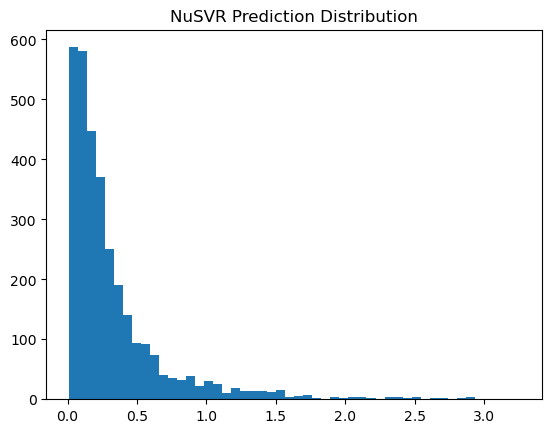

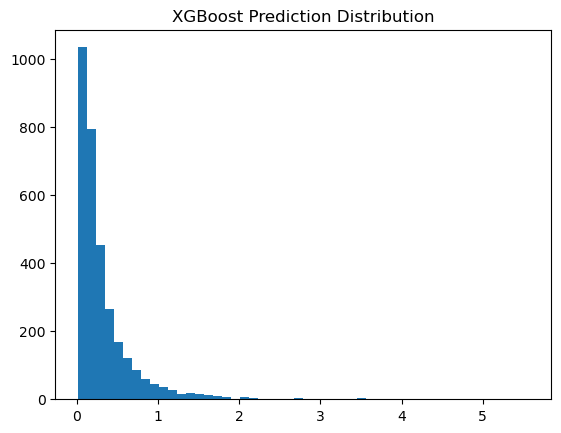

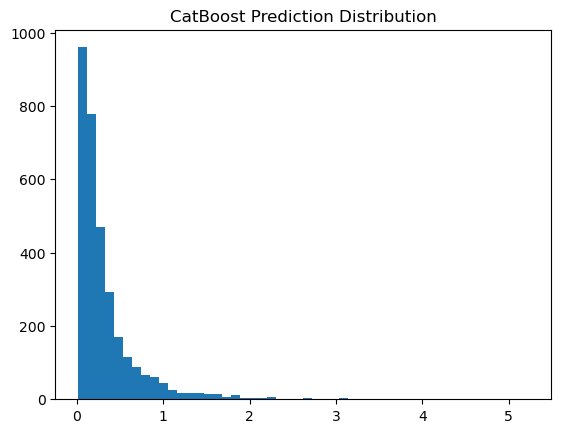

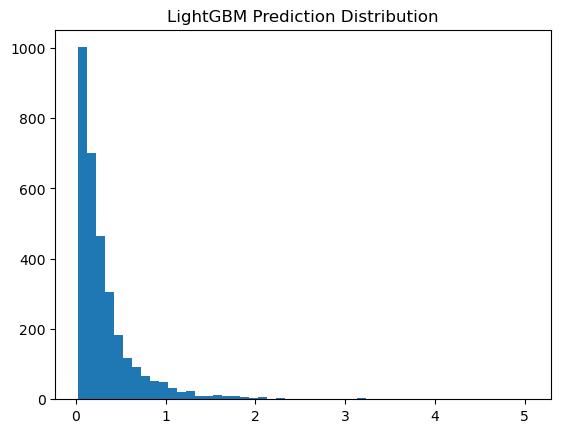

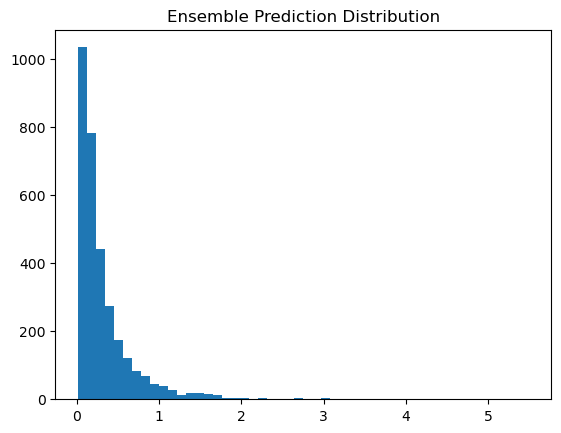

In [106]:
import matplotlib.pyplot as plt

plt.hist(nusvr_submission["Target Pressure (bar)"], bins=50)
plt.title("NuSVR Prediction Distribution")
plt.show()

plt.hist(xgb_submission["Target Pressure (bar)"], bins=50)
plt.title("XGBoost Prediction Distribution")
plt.show()

plt.hist(cat_submission["Target Pressure (bar)"], bins=50)
plt.title("CatBoost Prediction Distribution")
plt.show()

plt.hist(lightgbm_submission["Target Pressure (bar)"], bins=50)
plt.title("LightGBM Prediction Distribution")
plt.show()

plt.hist(ensemble_submission["Target Pressure (bar)"], bins=50)
plt.title("Ensemble Prediction Distribution")
plt.show()